# 03 · Bubble indicator dashboard

Results of the stored scan (`lppl scan`, run label `default`). For every analysis
date the **positive confidence** is the share of windows (125–750 trading days)
with a qualified fit and B < 0 (accelerating rise); the **negative confidence** the
share with B > 0 (accelerating decline).

> This is a research indicator, not investment advice.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lppl.data import db
from lppl import viz
viz.apply_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
engine = db.get_engine()          # reads POSTGRES_* env vars / .env (see docs/configuration.md)
assert db.ping(engine), "PostgreSQL not reachable - run `make up` first"


In [2]:
from lppl import pipeline
RUN = pipeline.resolve_run(engine, label="default")
runs = db.list_runs(engine)
display(runs[runs.run_id == RUN])
ind = db.load_indicator(engine, RUN)
inst = db.load_instruments(engine).set_index("ticker")
px = db.load_all_prices(engine, "adj_close")
print(f"{len(ind)} indicator rows · {ind.ticker.nunique()} tickers · {ind.date.min().date()} → {ind.date.max().date()}")

,run_id,created_at,finished_at,status,label,seed,git_sha
5,8264c9f6-03ad-4f8a-82b9-c6fcef75f023,2026-11-21 15:00:52.213876+00:00,2026-11-21 16:01:43.207311+00:00,finished,default,42,None


2388 indicator rows · 12 tickers · 2019-01-07 → 2026-11-20


## Current reading

In [3]:
rep = pipeline.report(engine, RUN)
rep.insert(0, "name", inst.loc[rep.index, "name"])
rep.style.format({"pos_conf": "{:.2f}", "neg_conf": "{:.2f}", "pos_conf_60d_max": "{:.2f}",
                  "neg_conf_60d_max": "{:.2f}"}, na_rep="–").background_gradient(
    subset=["pos_conf", "pos_conf_60d_max"], cmap=viz.SEQUENTIAL, vmin=0, vmax=1)

,name,date,pos_conf,neg_conf,n_qualified,n_windows,tc_median_date,tc_q25_date,tc_q75_date,pos_conf_60d_max,neg_conf_60d_max
ticker,,,,,,,,,,,
JPM,JPMorgan Chase,2026-11-20 00:00:00,0.12,0.00,3,26,2027-01-20 00:00:00,2027-01-10 00:00:00,2027-01-31 00:00:00,0.38,0.00
AAPL,Apple,2026-11-20 00:00:00,0.04,0.00,1,26,2026-12-19 00:00:00,2026-12-19 00:00:00,2026-12-19 00:00:00,0.08,0.00
META,Meta Platforms,2026-11-20 00:00:00,0.00,0.00,0,26,–,–,–,0.00,0.00
TSLA,Tesla,2026-11-20 00:00:00,0.00,0.00,0,26,–,–,–,0.00,0.00
NFLX,Netflix,2026-11-20 00:00:00,0.00,0.00,0,26,–,–,–,0.00,0.00
NVDA,NVIDIA,2026-11-20 00:00:00,0.00,0.00,0,26,–,–,–,0.00,0.00
GOOGL,Alphabet,2026-11-20 00:00:00,0.00,0.00,0,26,–,–,–,0.00,0.00
MSFT,Microsoft,2026-11-20 00:00:00,0.00,0.00,0,26,–,–,–,0.04,0.00
AVGO,Broadcom,2026-11-20 00:00:00,0.00,0.00,0,26,–,–,–,0.00,0.00


## Signed confidence heatmap

Red cells: bubble-like (positive) signatures; blue cells: anti-bubble (negative)
signatures; gray: nothing. Monthly maximum of each indicator.

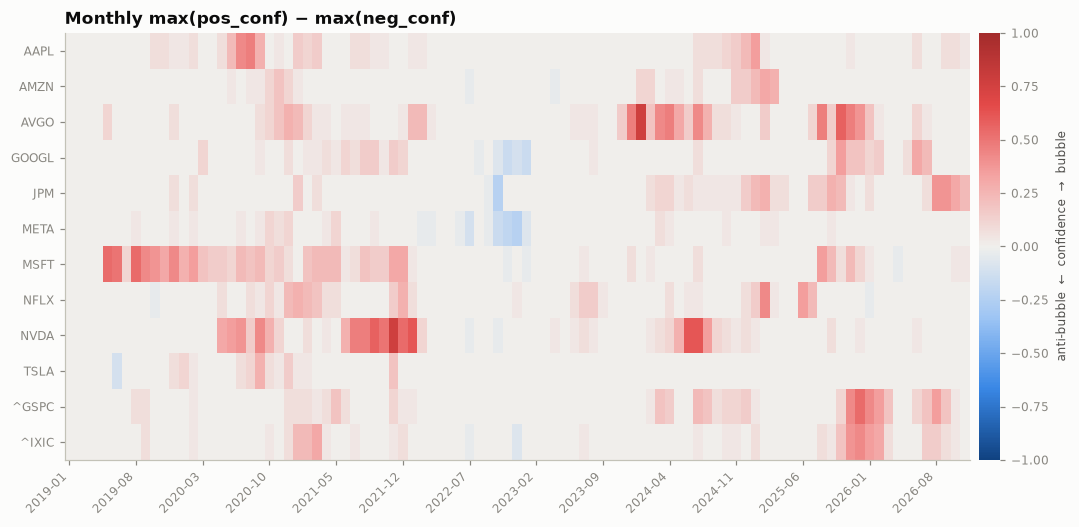

In [4]:
from pathlib import Path
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
viz.signed_heatmap(ind)
plt.title("Monthly max(pos_conf) − max(neg_conf)")
plt.savefig(FIG / "heatmap_default.png", bbox_inches="tight")
plt.show()

## Per-ticker detail

Top panel: price (log scale) with light red shading where the positive confidence
is ≥ 0.3. Bottom panel: positive confidence (up, red) and negative confidence (down, blue).

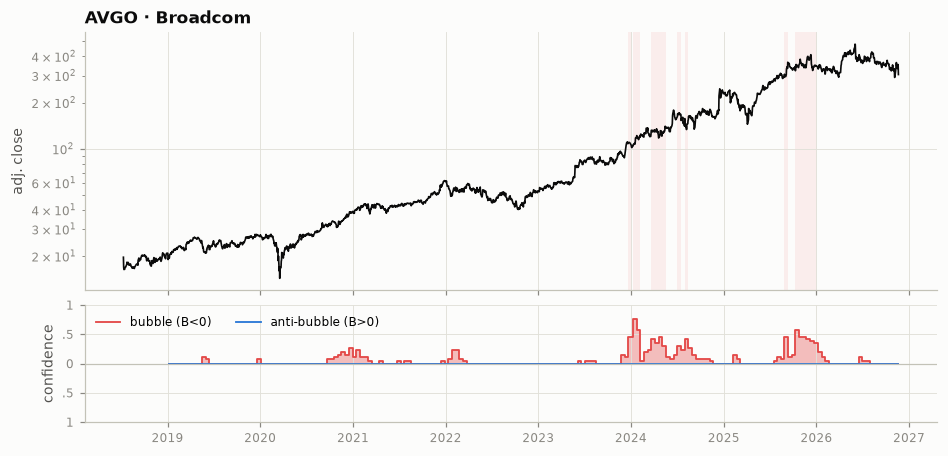

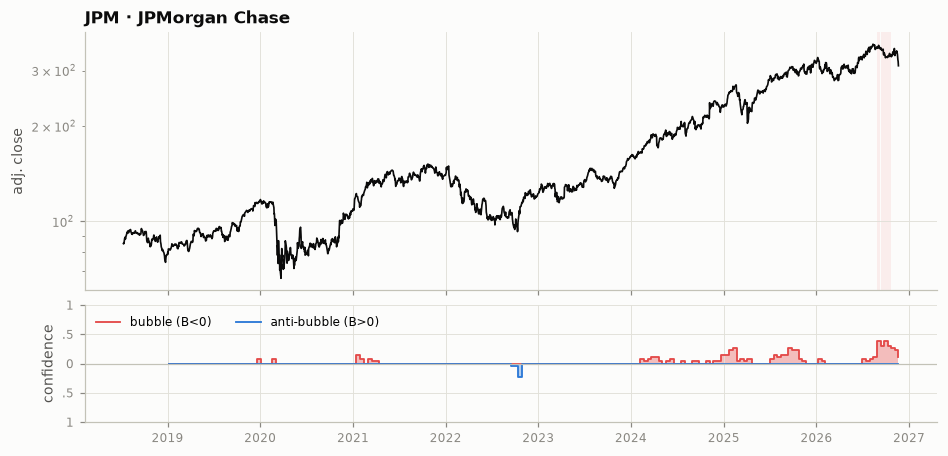

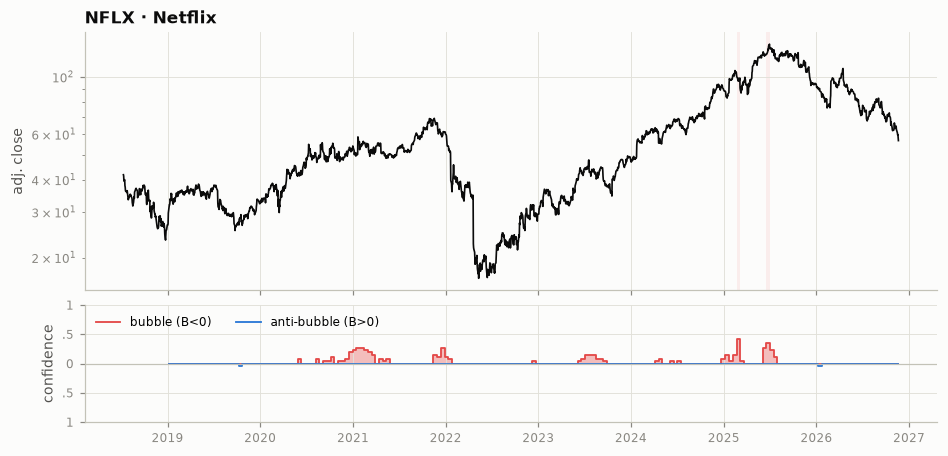

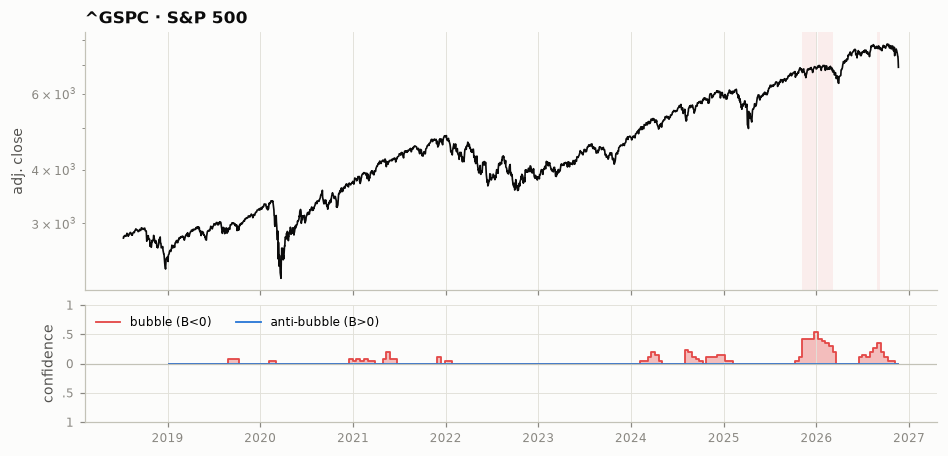

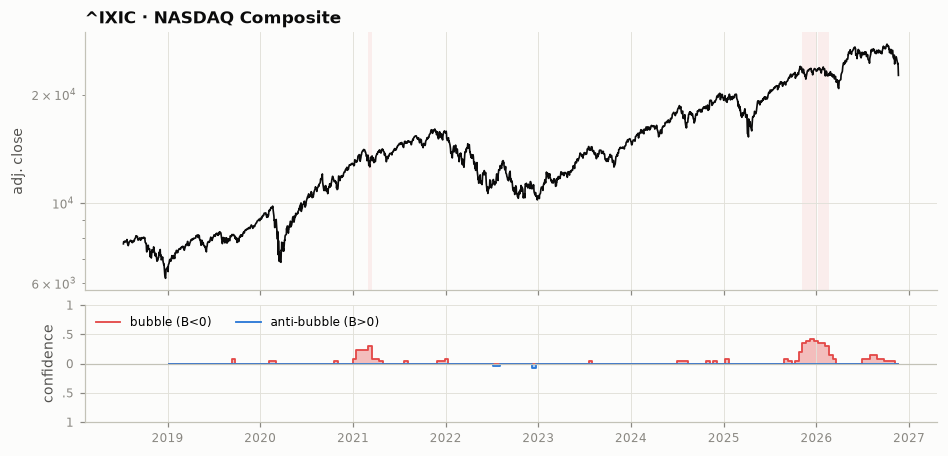

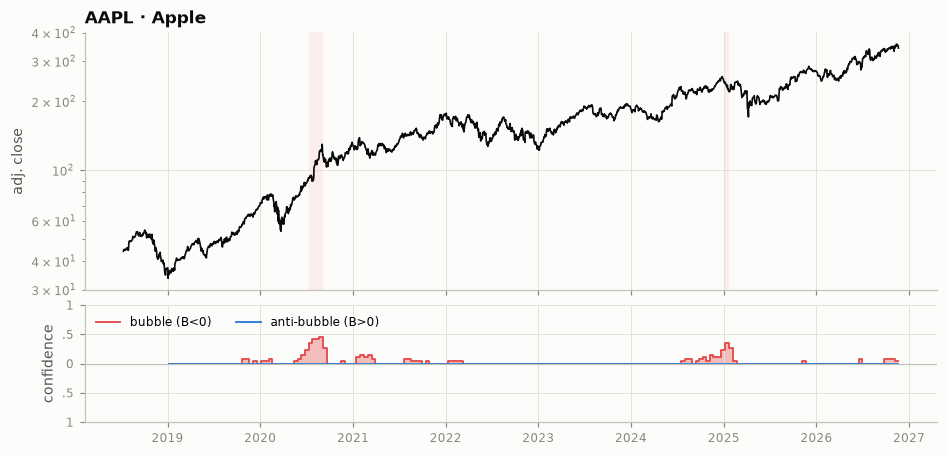

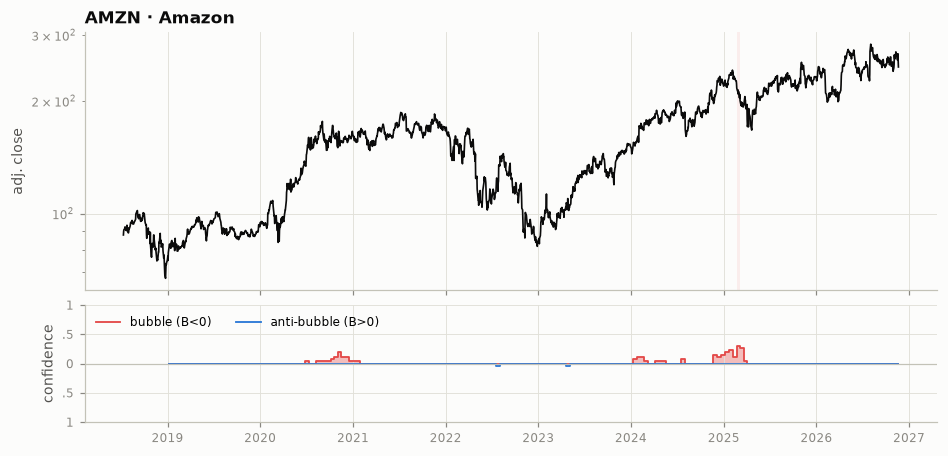

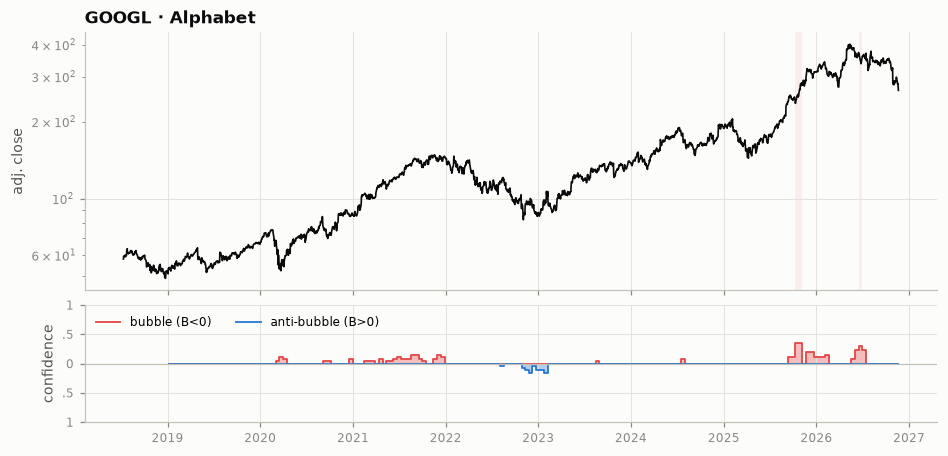

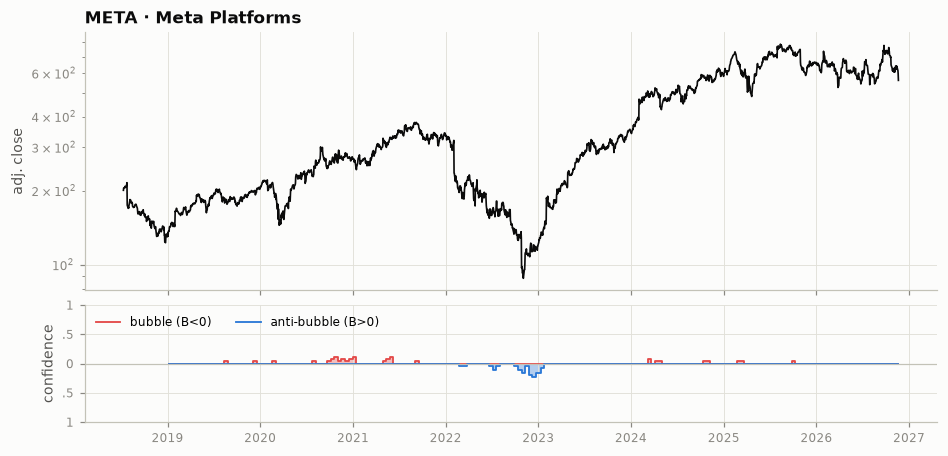

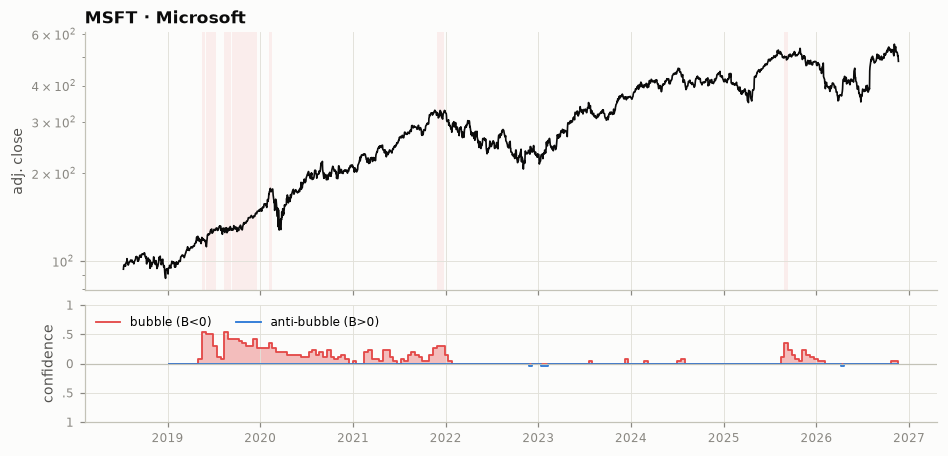

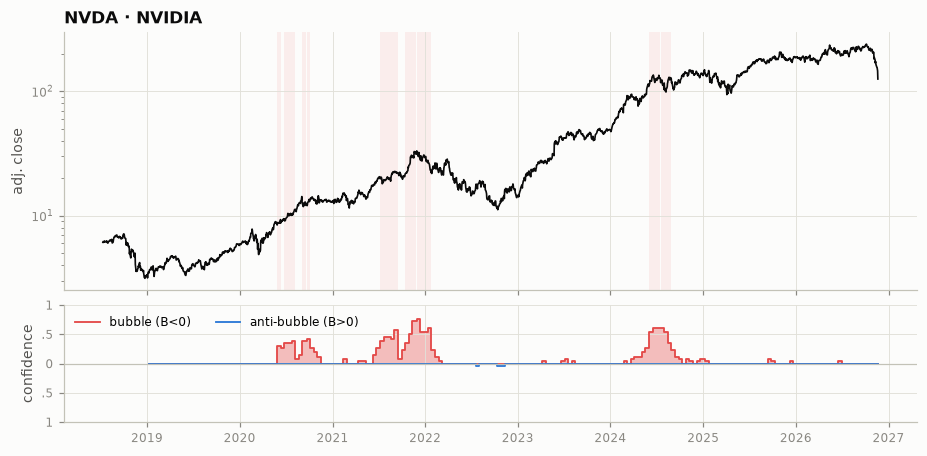

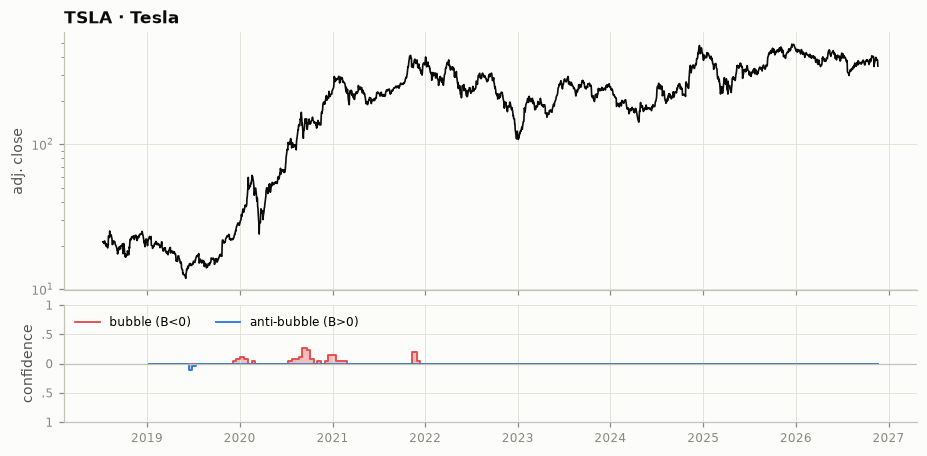

In [5]:
start = ind.date.min() - pd.Timedelta(days=180)
for t in inst.loc[ind.ticker.unique()].sort_values("grp").index:
    viz.price_and_confidence(px[t].loc[start:].dropna(), ind[ind.ticker == t], f"{t} · {inst.loc[t, 'name']}")
    if t in ("NVDA", "^GSPC", "AVGO"):
        plt.savefig(FIG / f"ticker_{t.strip('^')}.png", bbox_inches="tight")
    plt.show()

## Critical-time distribution at the latest date

For tickers with qualified fits on the last analysis date, the interquartile range
of the estimated critical time tc across windows.

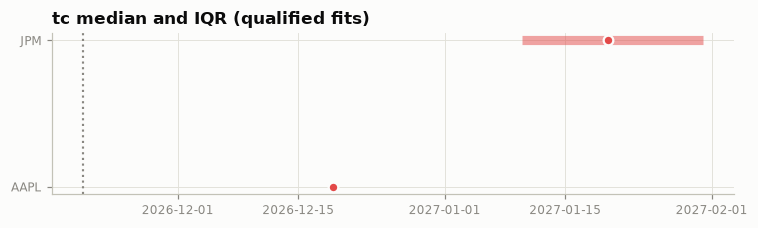

In [6]:
last = ind[ind.date == ind.date.max()].dropna(subset=["tc_median_date"]).sort_values("tc_median_date")
if last.empty:
    display(Markdown("_No qualified fits on the latest analysis date._"))
else:
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(last) + 1))
    yy = np.arange(len(last))
    ax.hlines(yy, last.tc_q25_date, last.tc_q75_date, color=viz.POS, lw=6, alpha=0.5)
    ax.scatter(last.tc_median_date, yy, color=viz.POS, s=40, zorder=3, edgecolor=viz.SURFACE, linewidth=1.5)
    ax.set_yticks(yy, last.ticker); ax.axvline(ind.date.max(), color=viz.MUTED, ls=":")
    ax.set_title("tc median and IQR (qualified fits)"); plt.show()

## Historical case studies

Runs labelled `case:*` (created by `make case-studies`) zoom on four well-known
episodes with a denser grid of analysis dates (every 5 trading days).

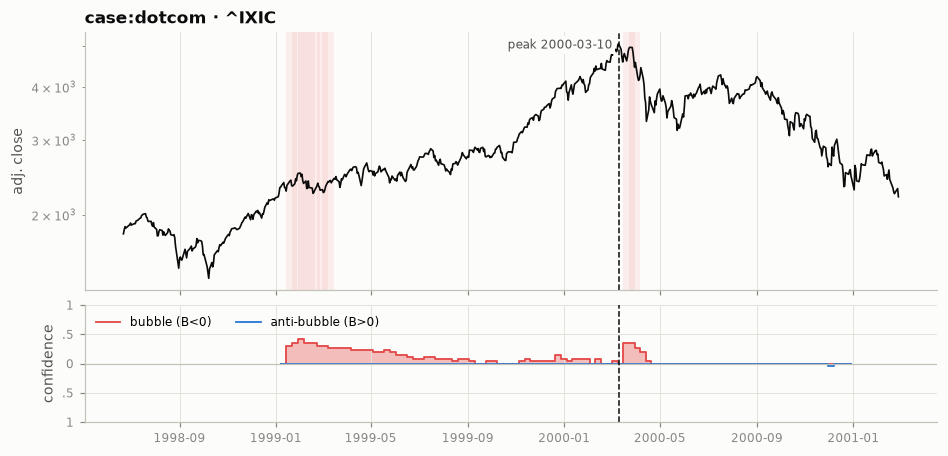

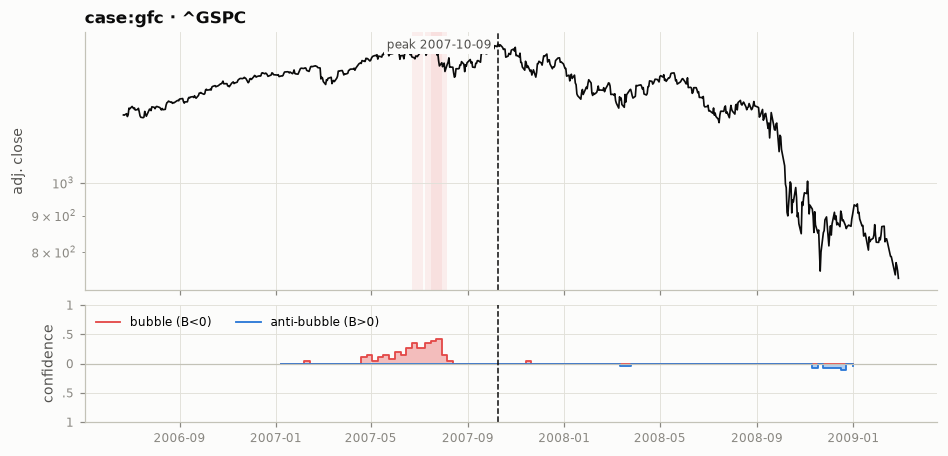

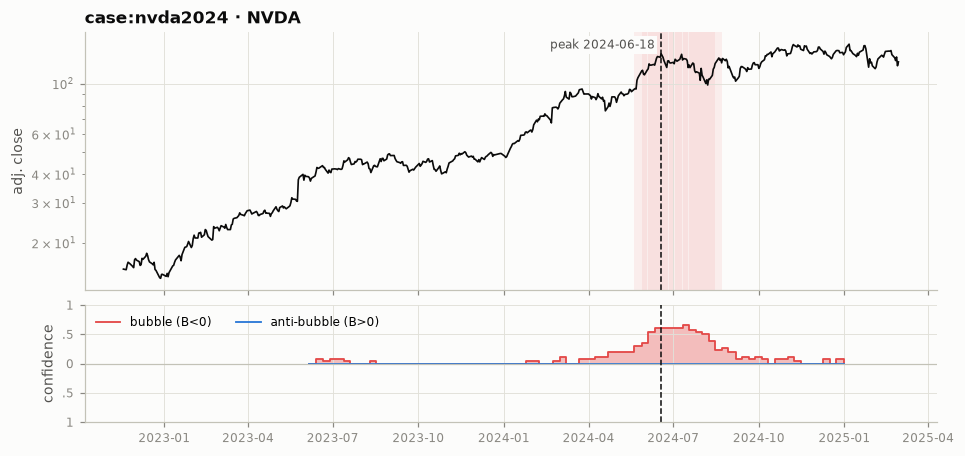

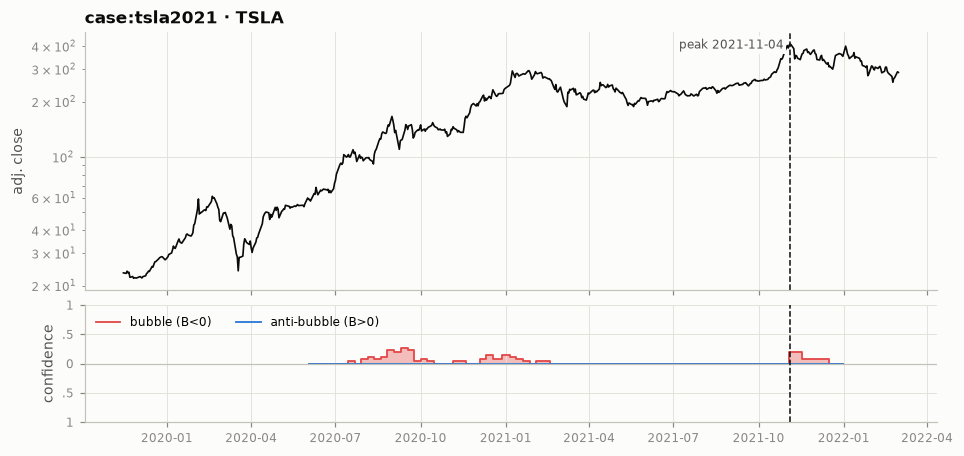

In [7]:
cases = db.load_indicator(engine, label="case:*")
CRASH = {"case:dotcom": "2000-03-10", "case:gfc": "2007-10-09", "case:tsla2021": "2021-11-04", "case:nvda2024": "2024-06-18"}
if cases.empty:
    display(Markdown("_No case-study runs yet: run `make case-studies`._"))
for label, g in cases.groupby("label"):
    t = g.ticker.iloc[0]
    a = viz.price_and_confidence(px[t].loc[g.date.min() - pd.Timedelta(days=200): g.date.max() + pd.Timedelta(days=60)].dropna(),
                                 g, f"{label} · {t}")
    if label in CRASH:
        for ax in a:
            ax.axvline(pd.Timestamp(CRASH[label]), color=viz.INK, ls="--", lw=1)
        a[0].annotate(f"peak {CRASH[label]}", (pd.Timestamp(CRASH[label]), a[0].get_ylim()[1]), fontsize=8,
                      color=viz.INK_2, ha="right", va="top", xytext=(-4, -4), textcoords="offset points",
                      bbox=dict(fc=viz.SURFACE, ec="none", pad=1.5))
    plt.savefig(FIG / f"{label.replace(':', '_')}.png", bbox_inches="tight")
    plt.show()